# Traffic Accident Severity Prediction (NHTSA FARS) — CS 746 PDS
Person-level injury severity (None / Minor-Possible / Serious / Fatal) from FARS crash, vehicle and person tables.
Models: Logistic Regression, Random Forest, XGBoost. Grouped train/test split by crash.

In [1]:
import os, re, io, json, time, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

YEARS = [2020, 2021, 2022]      # 3 years is enough for a 50% update
RUN_TUNE = False                # set True for randomised XGBoost tuning (slower)
RUN_SHAP = False                # set True for SHAP plot
SAMPLE = 0                      # >0 to subsample rows while debugging
SEED = 42

WORK = Path(os.environ.get("WORK_DIR", "/kaggle/working" if Path("/kaggle/working").exists() else "."))
RAW = Path(os.environ.get("FARS_RAW_DIR", WORK / "data" / "raw"))
RES = WORK / "results"; FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True); RAW.mkdir(parents=True, exist_ok=True)
print("work dir:", WORK)

work dir: /kaggle/working


## 1. Get the data

In [2]:
import requests
URL = "https://static.nhtsa.gov/nhtsa/downloads/FARS/{y}/National/FARS{y}NationalCSV.zip"

def find_csv(folder, table):
    for p in Path(folder).rglob("*"):
        if p.is_file() and p.name.lower() == f"{table.lower()}.csv":
            return p

# 1) any attached Kaggle input / earlier download with the three tables
year_dirs = {}
roots = [RAW] + ([Path("/kaggle/input")] if Path("/kaggle/input").exists() else [])
for root in roots:
    for p in root.rglob("*"):
        if p.is_file() and p.name.lower() == "accident.csv":
            m = re.search(r"(20\d\d|19\d\d)", str(p.relative_to(root)))
            if m and find_csv(p.parent, "person") and find_csv(p.parent, "vehicle"):
                year_dirs.setdefault(int(m.group(1)), p.parent)

# 2) download whatever is missing
for y in YEARS:
    if y in year_dirs: continue
    try:
        r = requests.get(URL.format(y=y), timeout=300); r.raise_for_status()
        d = RAW / str(y); d.mkdir(parents=True, exist_ok=True)
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(d)
        year_dirs[y] = d; print("downloaded", y)
    except Exception as e:
        print(f"!! could not download {y}: {e}")

YEARS = [y for y in YEARS if y in year_dirs]
assert YEARS, "No FARS data found. Turn Internet ON or attach a FARS dataset as Input."
print("using years:", YEARS)

downloaded 2020
downloaded 2021
downloaded 2022
using years: [2020, 2021, 2022]


## 2. Load, join, clean

In [3]:
ACCIDENT_COLS = ["ST_CASE","STATE","MONTH","DAY_WEEK","HOUR","FUNC_SYS","RUR_URB","TYP_INT","REL_ROAD","MAN_COLL",
                 "LGT_COND","WEATHER","SCH_BUS","VE_TOTAL","PERSONS","DRUNK_DR","FATALS","LATITUDE","LONGITUD"]
VEHICLE_COLS = ["ST_CASE","VEH_NO","TRAV_SP","SPEEDREL","BODY_TYP","MOD_YEAR","ROLLOVER","IMPACT1","DEFORMED","FIRE_EXP","HIT_RUN"]
PERSON_COLS = ["ST_CASE","VEH_NO","PER_NO","AGE","SEX","PER_TYP","SEAT_POS","REST_USE","AIR_BAG","EJECTION","ALC_RES","INJ_SEV"]
CATEGORICAL = ["STATE","MONTH","DAY_WEEK","FUNC_SYS","RUR_URB","TYP_INT","REL_ROAD","MAN_COLL","LGT_COND","WEATHER",
               "SPEEDREL","BODY_TYP","ROLLOVER","IMPACT1","DEFORMED","FIRE_EXP","HIT_RUN","SEX","PER_TYP","SEAT_POS",
               "REST_USE","AIR_BAG","EJECTION"]
NUMERIC = ["HOUR","VE_TOTAL","PERSONS","DRUNK_DR","LATITUDE","LONGITUD","TRAV_SP","MOD_YEAR","AGE","ALC_RES"]
UNKNOWN = {"HOUR":[99],"TRAV_SP":[997,998,999],"AGE":[998,999],"MOD_YEAR":[9998,9999],
           "LATITUDE":[77.7777,88.8888,99.9999],"LONGITUD":[777.7777,888.8888,999.9999],"ALC_RES":[95,96,97,98,99]}
LABELS = ["None","Minor/Possible","Serious","Fatal"]
INJ_MAP = {0:0, 1:1, 2:1, 3:2, 4:3}     # 5, 6, 9 (unknown / died prior) dropped
# never used as predictors: INJ_SEV, FATALS, DEATH_*

def read(folder, table, cols):
    df = pd.read_csv(find_csv(folder, table), encoding="latin-1", low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    return df[[c for c in cols if c in df.columns]].copy()

frames = []
for y in YEARS:
    acc, veh, per = read(year_dirs[y],"ACCIDENT",ACCIDENT_COLS), read(year_dirs[y],"VEHICLE",VEHICLE_COLS), read(year_dirs[y],"PERSON",PERSON_COLS)
    d = per.merge(veh, on=["ST_CASE","VEH_NO"], how="left").merge(acc, on="ST_CASE", how="left")
    d["YEAR"] = y; frames.append(d); print(y, f"{len(d):,} person records")
df = pd.concat(frames, ignore_index=True)
n_raw = len(df)

df = df.drop_duplicates()
df = df[df["INJ_SEV"].isin(INJ_MAP)].copy()
df["SEVERITY"] = df["INJ_SEV"].map(INJ_MAP).astype(int)
for c, codes in UNKNOWN.items():
    if c in df: df[c] = df[c].where(~df[c].isin(codes), np.nan)
df.loc[(df["AGE"]<0)|(df["AGE"]>110), "AGE"] = np.nan
df.loc[df["TRAV_SP"]>220, "TRAV_SP"] = np.nan
df["VEH_AGE"] = (df["YEAR"] - df["MOD_YEAR"]).clip(0, 40)
df["NIGHT"] = df["HOUR"].isin(list(range(0,6))+list(range(19,24))).astype(float).where(df["HOUR"].notna())
df["WEEKEND"] = df["DAY_WEEK"].isin([1,6,7]).astype(int)
df["GROUP"] = df["YEAR"].astype(str) + "_" + df["ST_CASE"].astype(str)
if SAMPLE: df = df.sample(min(SAMPLE, len(df)), random_state=SEED)

cat = [c for c in CATEGORICAL if c in df]; num = [c for c in NUMERIC+["VEH_AGE","NIGHT","WEEKEND"] if c in df]
print(f"\nrows: {n_raw:,} raw -> {len(df):,} after cleaning | crashes: {df['GROUP'].nunique():,} | features: {len(cat)} categorical + {len(num)} numeric")
dist = df["SEVERITY"].map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
print(pd.DataFrame({"count": dist, "percent": (dist/dist.sum()*100).round(2)}))

2020 86,396 person records
2021 97,511 person records
2022 96,186 person records

rows: 280,093 raw -> 274,627 after cleaning | crashes: 115,142 | features: 23 categorical + 13 numeric
                 count  percent
SEVERITY                       
None             71828    26.15
Minor/Possible   48810    17.77
Serious          29031    10.57
Fatal           124958    45.50


## 3. Exploratory data analysis

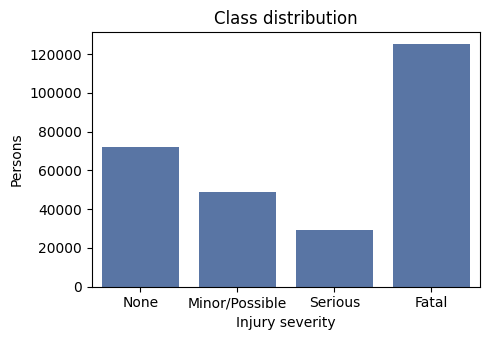

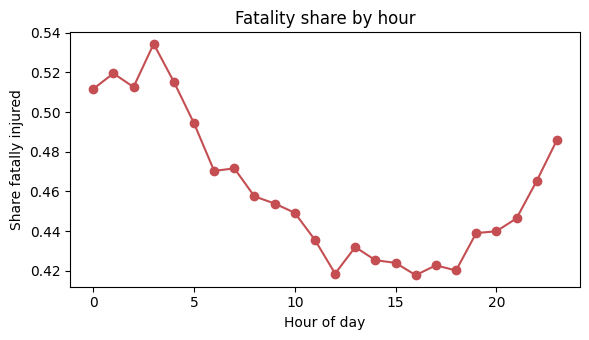

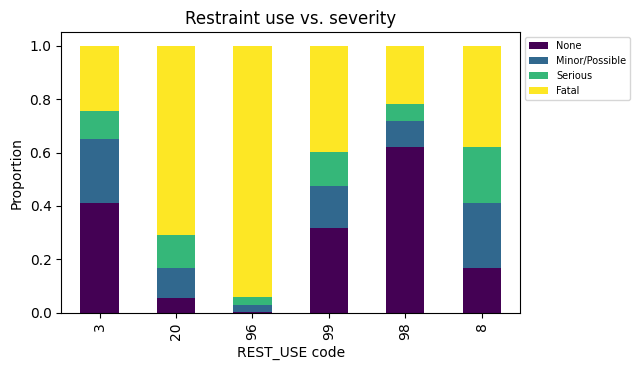

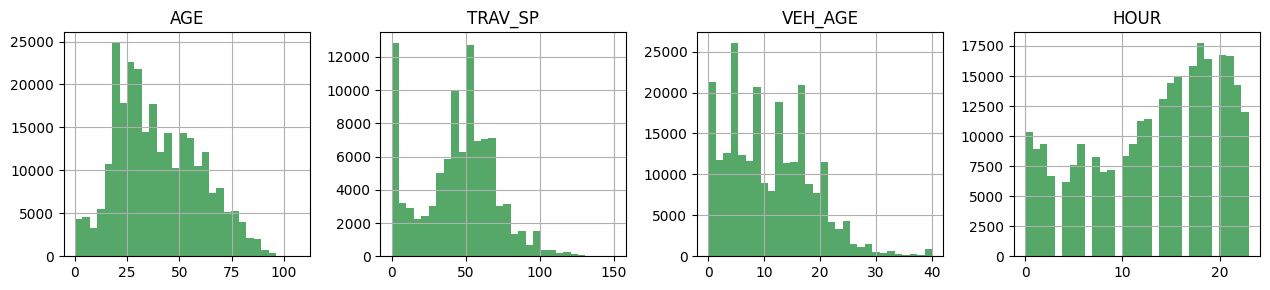

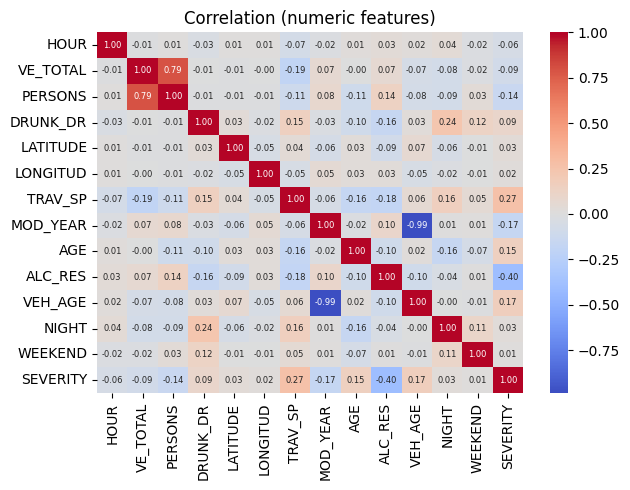

STATE       69.12
DRUNK_DR    69.12
TRAV_SP     63.43
VEH_AGE     11.47
MOD_YEAR    11.47
FIRE_EXP    10.28
ROLLOVER    10.28
DEFORMED    10.28
SPEEDREL    10.28
BODY_TYP    10.28
dtype: float64


In [4]:
df["SEV_LABEL"] = df["SEVERITY"].map(dict(enumerate(LABELS)))

fig, ax = plt.subplots(figsize=(5,3.5)); sns.countplot(data=df, x="SEV_LABEL", order=LABELS, ax=ax, color="#4C72B0")
ax.set_xlabel("Injury severity"); ax.set_ylabel("Persons"); ax.set_title("Class distribution")
fig.tight_layout(); fig.savefig(FIG/"eda_class_distribution.png", dpi=200); plt.show()

h = df.dropna(subset=["HOUR"]).groupby("HOUR")["SEVERITY"].apply(lambda s: (s==3).mean())
fig, ax = plt.subplots(figsize=(6,3.5)); h.plot(marker="o", ax=ax, color="#C44E52")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Share fatally injured"); ax.set_title("Fatality share by hour")
fig.tight_layout(); fig.savefig(FIG/"eda_hour_fatal_share.png", dpi=200); plt.show()

ct = pd.crosstab(df["REST_USE"], df["SEV_LABEL"], normalize="index")[LABELS]
ct = ct.loc[df["REST_USE"].value_counts().head(6).index]
fig, ax = plt.subplots(figsize=(6.5,3.8)); ct.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_xlabel("REST_USE code"); ax.set_ylabel("Proportion"); ax.set_title("Restraint use vs. severity")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1,1))
fig.tight_layout(); fig.savefig(FIG/"eda_restraint_severity.png", dpi=200); plt.show()

cols = [c for c in ["AGE","TRAV_SP","VEH_AGE","HOUR"] if c in df]
fig, axes = plt.subplots(1, len(cols), figsize=(3.2*len(cols),3))
for ax, c in zip(axes, cols): df[c].dropna().hist(bins=30, ax=ax, color="#55A868"); ax.set_title(c)
fig.tight_layout(); fig.savefig(FIG/"eda_histograms.png", dpi=200); plt.show()

corr = df[[c for c in num if df[c].notna().any()]+["SEVERITY"]].corr()
fig, ax = plt.subplots(figsize=(6.5,5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size":6})
ax.set_title("Correlation (numeric features)"); fig.tight_layout(); fig.savefig(FIG/"eda_correlation.png", dpi=200); plt.show()

miss = (df[cat+num].isna().mean()*100).sort_values(ascending=False).round(2)
miss.to_csv(RES/"missing_values_pct.csv", header=["pct_missing"]); print(miss.head(10))

## 4. Models and evaluation (grouped 80/20 split by crash)

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

def pre(scale):
    ns = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(ns), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005))]), cat)])

X, y, groups = df[cat+num], df["SEVERITY"].values, df["GROUP"].values
classes = sorted(np.unique(y))
tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y[tr], y[te]
print(f"train={len(tr):,}  test={len(te):,}  classes={classes}")

models = {
  "Logistic Regression": Pipeline([("pre", pre(True)),  ("clf", LogisticRegression(max_iter=300, class_weight="balanced"))]),
  "Random Forest": Pipeline([("pre", pre(False)), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                     class_weight="balanced_subsample", random_state=SEED))]),
  "XGBoost": Pipeline([("pre", pre(False)), ("clf", XGBClassifier(objective="multi:softprob", num_class=len(classes), n_estimators=400,
                     learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                     eval_metric="mlogloss", n_jobs=-1, random_state=SEED))]),
}

def evaluate(name, yt, proba):
    pred = proba.argmax(1)
    p, r, f, s = precision_recall_fscore_support(yt, pred, labels=classes, zero_division=0)
    yb = label_binarize(yt, classes=classes)
    auc = {LABELS[c]: float(roc_auc_score(yb[:,i], proba[:,i])) for i, c in enumerate(classes) if yb[:,i].sum() > 0}
    return {"model": name, "accuracy": float((pred==yt).mean()), "macro_precision": float(p.mean()), "macro_recall": float(r.mean()),
            "macro_f1": float(f.mean()), "weighted_f1": float(f1_score(yt, pred, average="weighted")),
            "roc_auc_macro_ovr": float(np.mean(list(auc.values()))),
            "per_class": {LABELS[c]: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i]),
                                      "roc_auc": auc.get(LABELS[c])} for i, c in enumerate(classes)},
            "confusion_matrix": confusion_matrix(yt, pred, labels=classes).tolist()}

results, probas, fitted = [], {}, {}
for name, pipe in models.items():
    t0 = time.time()
    if name == "XGBoost":
        sw = compute_sample_weight("balanced", ytr)
        if RUN_TUNE:
            s = RandomizedSearchCV(pipe, {"clf__max_depth":[4,6,8,10], "clf__learning_rate":[0.03,0.05,0.1],
                    "clf__n_estimators":[200,400,600], "clf__subsample":[0.7,0.8,1.0], "clf__colsample_bytree":[0.6,0.8,1.0],
                    "clf__min_child_weight":[1,5,10]}, n_iter=10, scoring="f1_macro", cv=GroupKFold(5), random_state=SEED, n_jobs=1)
            s.fit(Xtr, ytr, groups=groups[tr], clf__sample_weight=sw); pipe = s.best_estimator_
            json.dump(s.best_params_, open(RES/"xgb_best_params.json","w"), indent=2); print("best params:", s.best_params_)
        else:
            pipe.fit(Xtr, ytr, clf__sample_weight=sw)
    else:
        pipe.fit(Xtr, ytr)
    proba = pipe.predict_proba(Xte); res = evaluate(name, yte, proba); res["train_seconds"] = round(time.time()-t0, 1)
    results.append(res); probas[name] = proba; fitted[name] = pipe
    print(f"\n=== {name}: acc={res['accuracy']:.3f} macroF1={res['macro_f1']:.3f} AUC={res['roc_auc_macro_ovr']:.3f} ({res['train_seconds']}s)")
    print(classification_report(yte, proba.argmax(1), labels=classes, target_names=[LABELS[c] for c in classes], zero_division=0))

json.dump({"n_train": len(tr), "n_test": len(te), "years": YEARS, "n_rows": len(df), "results": results}, open(RES/"metrics.json","w"), indent=2)
table = pd.DataFrame([{k:v for k,v in r.items() if k not in ("per_class","confusion_matrix")} for r in results]).round(4)
table.to_csv(RES/"metrics_table.csv", index=False); table

train=219,968  test=54,659  classes=[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

=== Logistic Regression: acc=0.677 macroF1=0.604 AUC=0.876 (30.0s)
                precision    recall  f1-score   support

          None       0.81      0.77      0.79     14198
Minor/Possible       0.42      0.45      0.44      9547
       Serious       0.30      0.50      0.38      5859
         Fatal       0.89      0.75      0.81     25055

      accuracy                           0.68     54659
     macro avg       0.61      0.62      0.60     54659
  weighted avg       0.72      0.68      0.69     54659


=== Random Forest: acc=0.723 macroF1=0.637 AUC=0.900 (693.9s)
                precision    recall  f1-score   support

          None       0.82      0.77      0.79     14198
Minor/Possible       0.45      0.52      0.48      9547
       Serious       0.38      0.43      0.40      5859
         Fatal       0.89      0.84      0.87     25055

      accuracy                           0.72  

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_macro_ovr,train_seconds
0,Logistic Regression,0.6774,0.6056,0.6183,0.6042,0.6949,0.8764,30.0
1,Random Forest,0.7235,0.6360,0.6413,0.6372,0.7317,0.9002,693.9
2,XGBoost,0.7272,0.6502,0.6659,0.6505,0.7426,0.9101,36.0


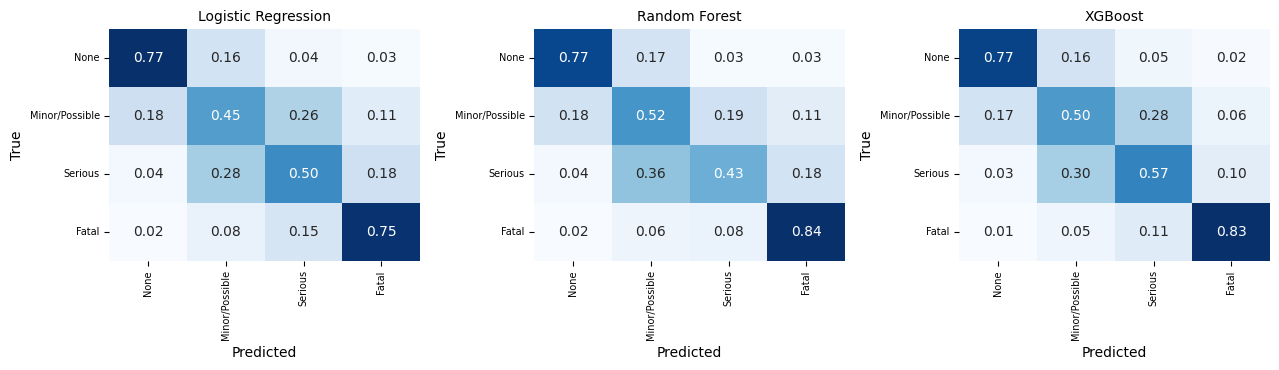

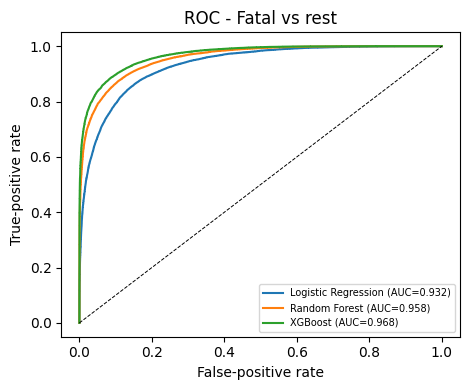

best by macro-F1: XGBoost


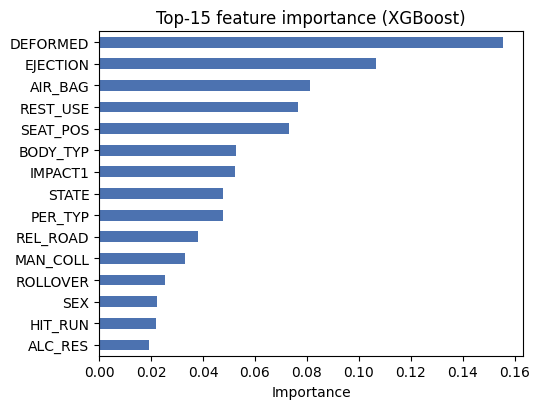

In [6]:
# Confusion matrices, ROC (Fatal vs rest), feature importance
fig, axes = plt.subplots(1, len(results), figsize=(4.3*len(results), 3.8))
for ax, r in zip(axes, results):
    cm = np.array(r["confusion_matrix"]); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False,
                xticklabels=[LABELS[c] for c in classes], yticklabels=[LABELS[c] for c in classes])
    ax.set_title(r["model"], fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG/"confusion_matrices.png", dpi=200); plt.show()

fatal = classes.index(3) if 3 in classes else len(classes)-1
yb = label_binarize(yte, classes=classes); fig, ax = plt.subplots(figsize=(4.8,4))
for n, pr in probas.items():
    fpr, tpr, _ = roc_curve(yb[:,fatal], pr[:,fatal]); ax.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(yb[:,fatal], pr[:,fatal]):.3f})")
ax.plot([0,1],[0,1],"k--",lw=.7); ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate"); ax.set_title("ROC - Fatal vs rest"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG/"roc_fatal.png", dpi=200); plt.show()

def importance(pipe):
    names = pipe.named_steps["pre"].get_feature_names_out(); clf = pipe.named_steps["clf"]
    imp = clf.feature_importances_ if hasattr(clf, "feature_importances_") else np.abs(clf.coef_).mean(0)
    origs = sorted(cat+num, key=len, reverse=True); agg = {}
    for n, v in zip(names, imp):
        b = n.split("__",1)[1]; k = next((o for o in origs if b == o or b.startswith(o+"_")), b); agg[k] = agg.get(k, 0)+float(v)
    return pd.Series(agg).sort_values(ascending=False)

for n, p in fitted.items(): importance(p).to_csv(RES/f"feature_importance_{n.replace(' ','_')}.csv")
best = max(results, key=lambda r: r["macro_f1"])["model"]; print("best by macro-F1:", best)
imp = importance(fitted[best]).head(15)[::-1]
fig, ax = plt.subplots(figsize=(5.5,4.2)); imp.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title(f"Top-15 feature importance ({best})"); ax.set_xlabel("Importance")
fig.tight_layout(); fig.savefig(FIG/"feature_importance.png", dpi=200); plt.show()

In [7]:
if RUN_SHAP:
    import shap
    pipe = fitted["XGBoost"]; Xs = Xte.sample(min(2000, len(Xte)), random_state=SEED)
    Z = pipe.named_steps["pre"].transform(Xs); Z = Z.toarray() if hasattr(Z, "toarray") else Z
    names = [n.split("__",1)[1] for n in pipe.named_steps["pre"].get_feature_names_out()]
    sv = shap.TreeExplainer(pipe.named_steps["clf"]).shap_values(Z); sv = np.stack(sv, -1) if isinstance(sv, list) else sv
    shap.summary_plot(sv[:,:,fatal], Z, feature_names=names, show=False, max_display=15)
    plt.savefig(FIG/"shap_fatal.png", dpi=200, bbox_inches="tight"); plt.show()

In [8]:
import shutil
shutil.make_archive(str(WORK/"results"), "zip", RES)
print("created", WORK/"results.zip"); print(sorted(p.name for p in RES.rglob("*") if p.is_file()))

created /kaggle/working/results.zip
['confusion_matrices.png', 'eda_class_distribution.png', 'eda_correlation.png', 'eda_histograms.png', 'eda_hour_fatal_share.png', 'eda_restraint_severity.png', 'feature_importance.png', 'feature_importance_Logistic_Regression.csv', 'feature_importance_Random_Forest.csv', 'feature_importance_XGBoost.csv', 'metrics.json', 'metrics_table.csv', 'missing_values_pct.csv', 'roc_fatal.png']
